# Aggressive vs Safe Action Trajectories

Given a vehicle state (extracted from a trajectory CSV row), this notebook:
1. Generates **aggressive** and **safe** constant-action sequences
2. Rolls them out using the **known F1TENTH dynamics** (single-track bicycle model)
3. Plots predicted trajectories overlaid on track and controller boundaries

## Action Classification

We classify actions along two axes:
- **Longitudinal intensity**: `|accel| / a_max` in [0, 1]
- **Lateral intensity**: `|sv| / sv_max` in [0, 1]

**Aggressiveness score** = `sqrt(a_norm^2 + s_norm^2) / sqrt(2)` in [0, 1]

| Category   | Score Range | Description |
|------------|------------|-------------|
| Safe       | < 0.3      | Gentle inputs, well within grip limits |
| Moderate   | 0.3 - 0.7  | Normal driving |
| Aggressive | > 0.7      | Pushing towards physical limits |

At **high friction** (mu=1.0), aggressive actions may still be safe.  
At **low friction** (mu=0.3), the same actions can cause loss of control.

In [1]:
import sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import yaml
from PIL import Image
from pathlib import Path

sys.path.insert(0, "..")
from src.track import Track

In [2]:
# ── Vehicle parameters (same as src/params.py defaults) ──────────────────
VP = dict(
    mu=1.0489, C_Sf=4.718, C_Sr=5.4562,
    lf=0.15875, lr=0.17145, h=0.074,
    m=3.74, I=0.04712,
    s_min=-0.4189, s_max=0.4189,
    sv_min=-3.2, sv_max=3.2,
    v_switch=7.319, a_max=9.51,
    v_min=-5.0, v_max=20.0,
    width=0.31, length=0.58,
)
G = 9.81
DT = 0.04  # timestep per action (same as controller)

In [3]:
# ── Known F1TENTH dynamics (single-track bicycle model) ─────────────────
# Matches src/dynamics/f1tenth_dynamics.py and the C++ simulator exactly.

def f1tenth_step(state_7, accel, sv, dt, mu_override=None):
    """
    One Euler step of the F1TENTH single-track dynamics.
    
    state_7: [x, y, delta, v, psi, omega, beta]
    accel: longitudinal acceleration (m/s^2)
    sv: steering velocity (rad/s)
    dt: timestep (s)
    mu_override: if set, overrides VP['mu'] for this step
    
    Returns: next_state (7,) numpy array
    """
    p = VP
    mu = mu_override if mu_override is not None else p['mu']
    
    x, y, delta, v, psi, omega, beta = state_7
    
    # Steering constraint
    if (delta <= p['s_min'] and sv <= 0) or (delta >= p['s_max'] and sv >= 0):
        sv = 0.0
    sv = max(p['sv_min'], min(p['sv_max'], sv))
    
    # Acceleration constraint
    if v > p['v_switch']:
        pos_limit = p['a_max'] * p['v_switch'] / (v + 1e-8)
    else:
        pos_limit = p['a_max']
    if (v <= p['v_min'] and accel <= 0) or (v >= p['v_max'] and accel >= 0):
        accel = 0.0
    accel = max(-p['a_max'], min(pos_limit, accel))
    
    L = p['lf'] + p['lr']
    
    if abs(v) < 0.5:
        # Kinematic model
        f_x = v * math.cos(psi)
        f_y = v * math.sin(psi)
        f_delta = sv
        f_v = accel
        f_psi = v / L * math.tan(delta)
        f_omega = accel / L * math.tan(delta) + v / (L * math.cos(delta)**2) * sv
        f_beta = 0.0
    else:
        # Dynamic model
        f_x = v * math.cos(beta + psi)
        f_y = v * math.sin(beta + psi)
        f_delta = sv
        f_v = accel
        f_psi = omega
        
        v_safe = max(abs(v), 0.5)
        f_omega = (
            -mu * p['m'] / (v_safe * p['I'] * L) * (
                p['lf']**2 * p['C_Sf'] * (G * p['lr'] - accel * p['h'])
                + p['lr']**2 * p['C_Sr'] * (G * p['lf'] + accel * p['h'])
            ) * omega
            + mu * p['m'] / (p['I'] * L) * (
                p['lr'] * p['C_Sr'] * (G * p['lf'] + accel * p['h'])
                - p['lf'] * p['C_Sf'] * (G * p['lr'] - accel * p['h'])
            ) * beta
            + mu * p['m'] / (p['I'] * L)
            * p['lf'] * p['C_Sf'] * (G * p['lr'] - accel * p['h']) * delta
        )
        f_beta = (
            (mu / (v_safe**2 * L) * (
                p['C_Sr'] * (G * p['lf'] + accel * p['h']) * p['lr']
                - p['C_Sf'] * (G * p['lr'] - accel * p['h']) * p['lf']
            ) - 1) * omega
            - mu / (v_safe * L) * (
                p['C_Sr'] * (G * p['lf'] + accel * p['h'])
                + p['C_Sf'] * (G * p['lr'] - accel * p['h'])
            ) * beta
            + mu / (v_safe * L)
            * p['C_Sf'] * (G * p['lr'] - accel * p['h']) * delta
        )
    
    # Euler integration
    next_state = np.array([
        x + dt * f_x,
        y + dt * f_y,
        delta + dt * f_delta,
        v + dt * f_v,
        (psi + dt * f_psi) % (2 * math.pi),
        omega + dt * f_omega,
        beta + dt * f_beta,
    ])
    return next_state


def rollout(state_7, actions, dt=DT, mu=None):
    """
    Roll out a sequence of actions from state_7.
    
    actions: list of (accel, sv) tuples, or (N, 2) array
    Returns: (N+1, 7) array of states (includes initial state)
    """
    actions = np.asarray(actions)
    traj = [np.array(state_7, dtype=float)]
    s = traj[0].copy()
    for a in actions:
        s = f1tenth_step(s, a[0], a[1], dt, mu_override=mu)
        traj.append(s.copy())
    return np.array(traj)

In [4]:
# ── Aggressiveness classification & sampling ───────────────────────────

def aggressiveness_score(accel, sv):
    """Compute aggressiveness score in [0, 1].
    
    score = sqrt((|accel|/a_max)^2 + (|sv|/sv_max)^2) / sqrt(2)
    """
    a_norm = abs(accel) / VP['a_max']
    s_norm = abs(sv) / VP['sv_max']
    return math.sqrt(a_norm**2 + s_norm**2) / math.sqrt(2)


def classify_action(accel, sv):
    score = aggressiveness_score(accel, sv)
    if score < 0.3:
        return 'safe'
    elif score < 0.7:
        return 'moderate'
    else:
        return 'aggressive'


def compute_slip_angle(state_7):
    """Compute rear slip angle from state."""
    v, beta = state_7[3], state_7[6]
    v_x = v * math.cos(beta)
    v_y = v * math.sin(beta)
    return -math.atan2(v_y, abs(v_x) + 1e-8)


def sample_actions(n, category, rng=None):
    """Sample n random (accel, sv) pairs within a category.
    
    Categories defined by aggressiveness score:
        'safe':       score < 0.3
        'moderate':   0.3 <= score < 0.7
        'aggressive': score >= 0.7
    
    Sampling uses polar coordinates in normalized action space:
        a_norm = accel / a_max in [-1, 1]
        s_norm = sv / sv_max   in [-1, 1]
        score  = r / sqrt(2)   where r = sqrt(a_norm^2 + s_norm^2)
    
    Returns: (n, 2) array of (accel, sv) pairs
    """
    if rng is None:
        rng = np.random.default_rng()
    
    score_ranges = {
        'safe':       (0.0, 0.3),
        'moderate':   (0.3, 0.7),
        'aggressive': (0.7, 1.0),
    }
    lo, hi = score_ranges[category]
    # Convert score bounds to radius in normalized space: r = score * sqrt(2)
    r_lo = lo * math.sqrt(2)
    r_hi = hi * math.sqrt(2)
    
    results = []
    while len(results) < n:
        # Over-sample then filter (rejection for square boundary)
        batch = max(n * 3, 1000)
        theta = rng.uniform(0, 2 * math.pi, batch)
        # Sample radius uniformly in area: r = sqrt(uniform(r_lo^2, r_hi^2))
        r = np.sqrt(rng.uniform(r_lo**2, r_hi**2, batch))
        a_norm = r * np.cos(theta)
        s_norm = r * np.sin(theta)
        # Keep only those within the [-1, 1] square
        mask = (np.abs(a_norm) <= 1.0) & (np.abs(s_norm) <= 1.0)
        a_norm = a_norm[mask]
        s_norm = s_norm[mask]
        for a, s in zip(a_norm, s_norm):
            results.append((a * VP['a_max'], s * VP['sv_max']))
            if len(results) >= n:
                break
    
    return np.array(results[:n])


# ── Demo: show sample counts and score ranges ─────────────────────────
rng = np.random.default_rng(42)
for cat in ['safe', 'moderate', 'aggressive']:
    samples = sample_actions(5, cat, rng)
    print(f"\n{cat.upper()} (5 samples):")
    for accel, sv in samples:
        score = aggressiveness_score(accel, sv)
        print(f"  accel={accel:>7.2f}  sv={sv:>6.2f}  score={score:.3f}")


SAFE (5 samples):
  accel=   0.15  sv= -0.33  score=0.075
  accel=  -2.53  sv=  0.34  score=0.203
  accel=   0.91  sv= -0.38  score=0.108
  accel=  -0.51  sv= -0.50  score=0.117
  accel=   2.66  sv=  0.60  score=0.239

MODERATE (5 samples):
  accel=   4.81  sv= -2.45  score=0.649
  accel=  -7.27  sv=  0.86  score=0.572
  accel=   5.58  sv= -0.57  score=0.434
  accel=  -4.89  sv= -2.29  score=0.623
  accel=   3.53  sv=  1.06  score=0.352

AGGRESSIVE (5 samples):
  accel=  -9.35  sv= -0.77  score=0.716
  accel=  -8.54  sv= -2.45  score=0.834
  accel=   9.37  sv= -1.49  score=0.771
  accel=  -9.48  sv= -1.38  score=0.768
  accel=  -6.56  sv= -3.12  score=0.844


In [5]:
# ── Load trajectory data ───────────────────────────────────────────────

CSV_PATH = (
    "../results/mcts_pi_svgp_cs_extract_YasMarina_10/"
    "traj_config_mcts_dpw_pi_svgp_cpp_cs_extract_s42_YasMarina_10_20260219_110439.csv"
)

TRACK_NAME = "YasMarina"
FRICTION_ID = "10489"  # for map/centerline paths

def load_trajectory_df(csv_path):
    df = pd.read_csv(csv_path, comment="#")
    for col in ['pred_vx', 'pred_vy', 'pred_omega']:
        if col in df.columns:
            df = df.drop(col, axis=1)
    # Parse semicolon-separated action lists (if present)
    for col in ['Aa_action_list', 'Asv_action_list']:
        if col in df.columns:
            df[col] = df[col].apply(
                lambda s: np.array([float(x) for x in str(s).split(';')])
                if pd.notna(s) and str(s).strip() else np.array([])
            )
    return df

df = load_trajectory_df(CSV_PATH)
print(f"Loaded {len(df)} rows from CSV")
print(f"Velocity range: [{df.S_vel.min():.2f}, {df.S_vel.max():.2f}] m/s")
print(f"Steering range: [{df.S_delta.min():.4f}, {df.S_delta.max():.4f}] rad")

Loaded 3048 rows from CSV
Velocity range: [0.00, 8.79] m/s
Steering range: [-0.4100, 0.4662] rad


In [6]:
# ── Load map and track boundaries ─────────────────────────────────────

MAPS_DIR = Path("../maps")

def load_map_and_track(track_name, friction_id, maps_dir=MAPS_DIR):
    map_dir = maps_dir / f"{track_name}_{friction_id}"
    
    # Map image
    map_img = np.array(
        Image.open(map_dir / f"{track_name}_map.png").transpose(Image.FLIP_TOP_BOTTOM)
    ).astype(np.float64)
    
    # Map metadata
    with open(map_dir / f"{track_name}_map.yaml") as f:
        meta = yaml.safe_load(f)
    res = meta["resolution"]
    ox, oy = meta["origin"][0], meta["origin"][1]
    h_px, w_px = map_img.shape[:2]
    extent = [ox, ox + w_px * res, oy, oy + h_px * res]
    
    # Track object
    centerline_path = str(map_dir / f"{track_name}_centerline.csv")
    track_obj = Track(centerline_path)
    
    return map_img, extent, track_obj

map_img, extent, track_obj = load_map_and_track(TRACK_NAME, FRICTION_ID)
print(f"Track: {track_obj.n_points} centerline pts, length = {track_obj.total_length:.1f} m")

Track: 1110 centerline pts, length = 398.0 m


In [7]:
# ── Main plotting function ─────────────────────────────────────────────

CATEGORY_COLORS = {
    'aggressive': 'red',
    'moderate': 'orange',
    'safe': 'green',
}

def plot_trajectories(
    row_idx,
    df,
    track_obj,
    map_img=None,
    extent=None,
    mu=None,
    horizon=10,
    lane_width=1.1,
    zoom_pad=3.0,
    figsize=(14, 10),
    n_aggressive=100,
    n_moderate=100,
    n_safe=100,
    seed=42,
):
    """
    Sample random action pairs per category, roll out, and plot.
    
    Parameters
    ----------
    row_idx : int
        Row in DataFrame for the starting state.
    mu : float or None
        Friction override for dynamics.
    horizon : int
        Number of action steps per rollout.
    lane_width : float
        Controller corridor width (meters).
    n_aggressive, n_moderate, n_safe : int
        Number of trajectories to sample per category. Set to 0 to skip.
    seed : int
        RNG seed for reproducibility.
    """
    row = df.iloc[row_idx]
    state0 = np.array([
        row.S_x, row.S_y, row.S_delta, row.S_vel,
        row.S_psi, row.S_omega, row.S_beta
    ])
    
    mu_label = f"{mu:.4f}" if mu is not None else f"{VP['mu']}"
    
    print(f"Starting state (row {row_idx}):")
    print(f"  x={state0[0]:.4f}  y={state0[1]:.4f}  delta={state0[2]:.4f}")
    print(f"  v={state0[3]:.2f} m/s  psi={state0[4]:.4f}  omega={state0[5]:.4f}  beta={state0[6]:.6f}")
    print(f"  mu={mu_label}  horizon={horizon}  dt={DT}")
    print(f"  Sampling: {n_aggressive} aggressive, {n_moderate} moderate, {n_safe} safe")
    
    rng = np.random.default_rng(seed)
    
    # Sample actions per category
    categories = []
    if n_aggressive > 0:
        categories.append(('aggressive', sample_actions(n_aggressive, 'aggressive', rng)))
    if n_moderate > 0:
        categories.append(('moderate', sample_actions(n_moderate, 'moderate', rng)))
    if n_safe > 0:
        categories.append(('safe', sample_actions(n_safe, 'safe', rng)))
    
    # Roll out all trajectories
    all_trajs = {}  # category -> list of (N+1, 7) arrays
    off_track_counts = {}
    for cat, action_pairs in categories:
        trajs = []
        n_off = 0
        for accel, sv in action_pairs:
            actions = [(accel, sv)] * horizon
            traj = rollout(state0, actions, dt=DT, mu=mu)
            trajs.append(traj)
            # Check corridor violation
            for pt in traj:
                _, dist, _ = track_obj.get_nearest_point(pt[:2])
                if dist > lane_width / 2:
                    n_off += 1
                    break
        all_trajs[cat] = trajs
        off_track_counts[cat] = n_off
    
    # ── Plot ────────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    
    # --- Left panel: spatial trajectories ---
    ax = axes[0]
    
    if map_img is not None:
        ax.imshow(map_img, extent=extent, origin='lower', cmap='gray', alpha=0.3)
    
    # Track boundaries
    ax.plot(track_obj.left_boundary[:, 0], track_obj.left_boundary[:, 1],
            '-', color='gray', linewidth=1.0, alpha=0.6)
    ax.plot(track_obj.right_boundary[:, 0], track_obj.right_boundary[:, 1],
            '-', color='gray', linewidth=1.0, alpha=0.6)
    
    # Controller corridor
    half_lw = lane_width / 2.0
    ctrl_left = track_obj.centerline + track_obj.normal * half_lw
    ctrl_right = track_obj.centerline - track_obj.normal * half_lw
    ax.plot(ctrl_left[:, 0], ctrl_left[:, 1],
            '--', color='purple', linewidth=1.0, alpha=0.7)
    ax.plot(ctrl_right[:, 0], ctrl_right[:, 1],
            '--', color='purple', linewidth=1.0, alpha=0.7)
    
    # Plot trajectories (safe first so aggressive draws on top)
    draw_order = ['safe', 'moderate', 'aggressive']
    for cat in draw_order:
        if cat not in all_trajs:
            continue
        color = CATEGORY_COLORS[cat]
        for traj in all_trajs[cat]:
            ax.plot(traj[:, 0], traj[:, 1], '-', color=color, linewidth=1.5, alpha=0.7)
    
    # Start marker + heading arrow
    ax.plot(state0[0], state0[1], '*', color='black', markersize=15, zorder=10)
    arrow_len = 0.3
    ax.annotate('', xy=(state0[0] + arrow_len * math.cos(state0[4]),
                        state0[1] + arrow_len * math.sin(state0[4])),
                xytext=(state0[0], state0[1]),
                arrowprops=dict(arrowstyle='->', color='black', lw=2))
    
    # Legend
    legend_items = []
    for cat in draw_order:
        if cat in all_trajs:
            n = len(all_trajs[cat])
            legend_items.append(mpatches.Patch(
                color=CATEGORY_COLORS[cat],
                label=f'{cat.capitalize()} (n={n})',
            ))
    ax.legend(handles=legend_items, loc='upper left', fontsize=10)
    
    # Zoom
    all_x = np.concatenate([t[:, 0] for trajs in all_trajs.values() for t in trajs])
    all_y = np.concatenate([t[:, 1] for trajs in all_trajs.values() for t in trajs])
    ax.set_xlim(all_x.min() - zoom_pad, all_x.max() + zoom_pad)
    ax.set_ylim(all_y.min() - zoom_pad, all_y.max() + zoom_pad)
    ax.set_aspect('equal')
    ax.set_xlabel('x [m]', fontsize=12)
    ax.set_ylabel('y [m]', fontsize=12)
    ax.set_title(f'Sampled trajectories from row {row_idx} (mu={mu_label})', fontsize=13)
    ax.grid(True, alpha=0.3)
    
    # --- Right panel: velocity distributions at final step ---
    ax2 = axes[1]
    
    for cat in draw_order:
        if cat not in all_trajs:
            continue
        v_finals = [t[-1, 3] for t in all_trajs[cat]]
        ax2.hist(v_finals, bins=30, alpha=0.5, color=CATEGORY_COLORS[cat],
                 label=f'{cat.capitalize()}', density=True)
    
    ax2.set_xlabel('Final velocity [m/s]', fontsize=12)
    ax2.set_ylabel('Density', fontsize=12)
    ax2.set_title(f'Velocity distribution at t={horizon * DT:.2f}s', fontsize=13)
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # ── Summary ────────────────────────────────────────────────────────
    print(f"\n{'Category':<15} {'Count':>6} {'Off-corridor':>13} {'%':>6}  {'v_end mean':>10} {'v_end std':>10}")
    print("-" * 70)
    for cat in draw_order:
        if cat not in all_trajs:
            continue
        n = len(all_trajs[cat])
        n_off = off_track_counts[cat]
        v_ends = [t[-1, 3] for t in all_trajs[cat]]
        print(f"{cat:<15} {n:>6} {n_off:>13} {100*n_off/n:>5.1f}%  {np.mean(v_ends):>10.2f} {np.std(v_ends):>10.2f}")
    
    return all_trajs, off_track_counts

## Usage

Change `ROW_IDX` to pick a different starting state.  
Change `MU` to see how friction affects which actions stay within the corridor.

Starting state (row 500):
  x=5.9023  y=61.8019  delta=-0.0239
  v=7.23 m/s  psi=4.4940  omega=-0.2552  beta=0.014732
  mu=0.3000  horizon=12  dt=0.04
  Sampling: 333 aggressive, 333 moderate, 333 safe


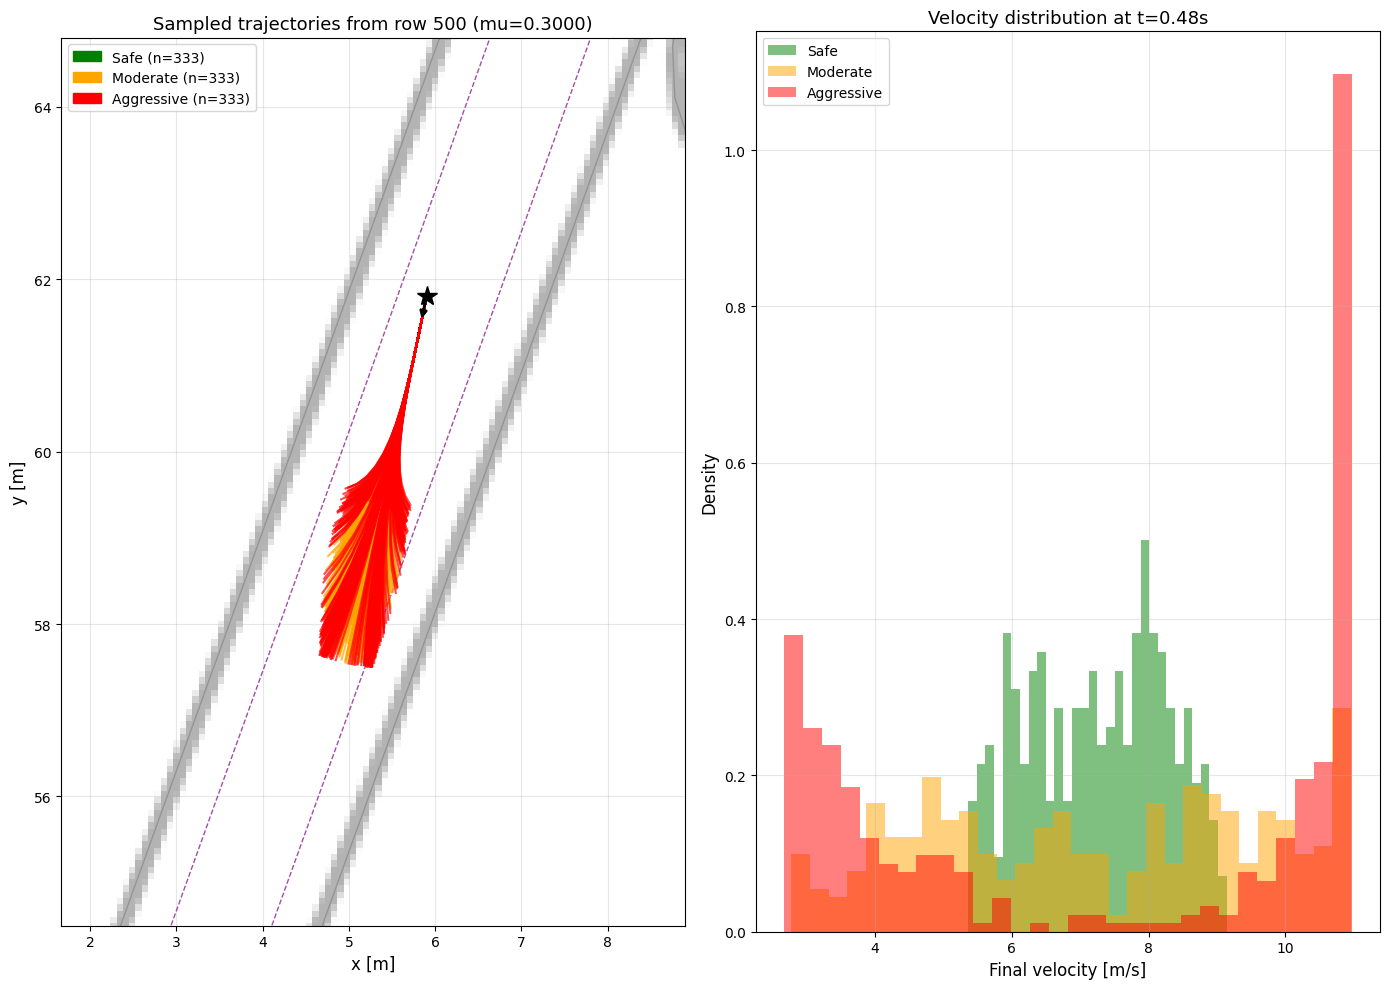


Category         Count  Off-corridor      %  v_end mean  v_end std
----------------------------------------------------------------------
safe               333             0   0.0%        7.25       0.99
moderate           333            12   3.6%        7.21       2.39
aggressive         333            84  25.2%        7.29       3.44


In [8]:
# ── High friction (mu = 1.0489) ───────────────────────────────────────
ROW_IDX = 500
MU = 0.3

trajs_high, off_high = plot_trajectories(
    ROW_IDX, df, track_obj,
    map_img=map_img, extent=extent,
    mu=MU, horizon=12, lane_width=1.1,
    # n_aggressive=5, n_moderate=5, n_safe=5,
    n_aggressive=333, n_moderate=333, n_safe=333,

)

Starting state (row 750):
  x=-18.5044  y=-8.3016  delta=0.0572
  v=3.99 m/s  psi=4.6761  omega=2.9461  beta=-0.074989
  mu=0.3000  horizon=20  dt=0.04
  Sampling: 333 aggressive, 333 moderate, 333 safe


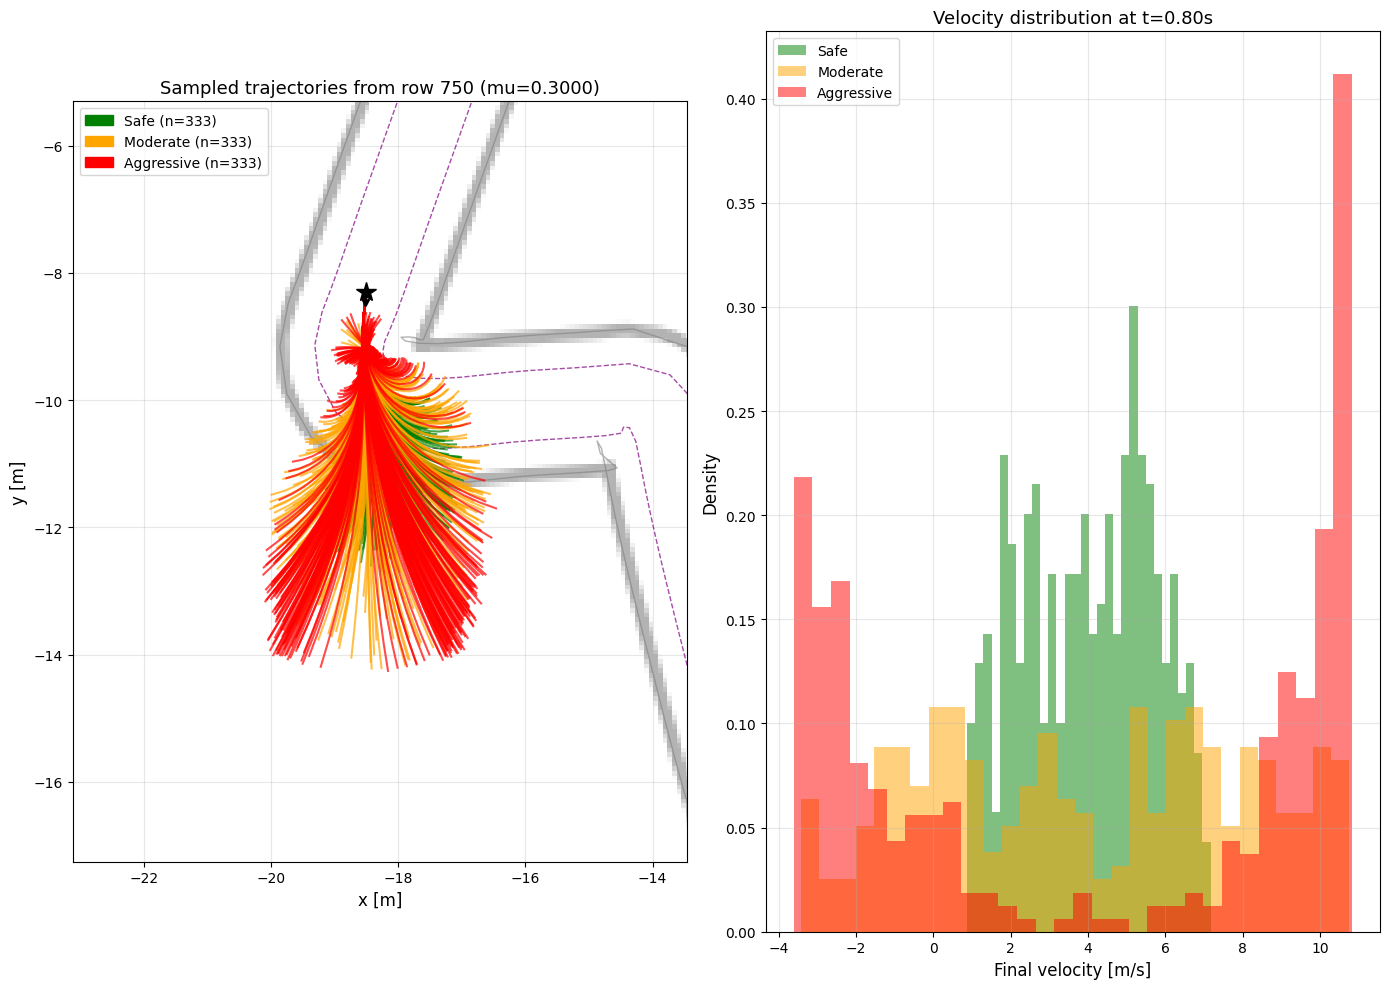


Category         Count  Off-corridor      %  v_end mean  v_end std
----------------------------------------------------------------------
safe               333             0   0.0%        4.02       1.66
moderate           333            20   6.0%        3.98       4.02
aggressive         333            27   8.1%        4.21       5.87


In [9]:
# ── High friction (mu = 1.0489) ──────────────────────────────────────────
ROW_IDX = 750
MU = 0.3

trajs_high, off_high = plot_trajectories(
    ROW_IDX, df, track_obj,
    map_img=map_img, extent=extent,
    mu=MU, horizon=20, lane_width=1.1,
        n_aggressive=333, n_moderate=333, n_safe=333,

)

Starting state (row 750):
  x=-18.5044  y=-8.3016  delta=0.0572
  v=3.99 m/s  psi=4.6761  omega=2.9461  beta=-0.074989
  mu=0.3000  horizon=15  dt=0.04
  Sampling: 200 aggressive, 200 moderate, 200 safe


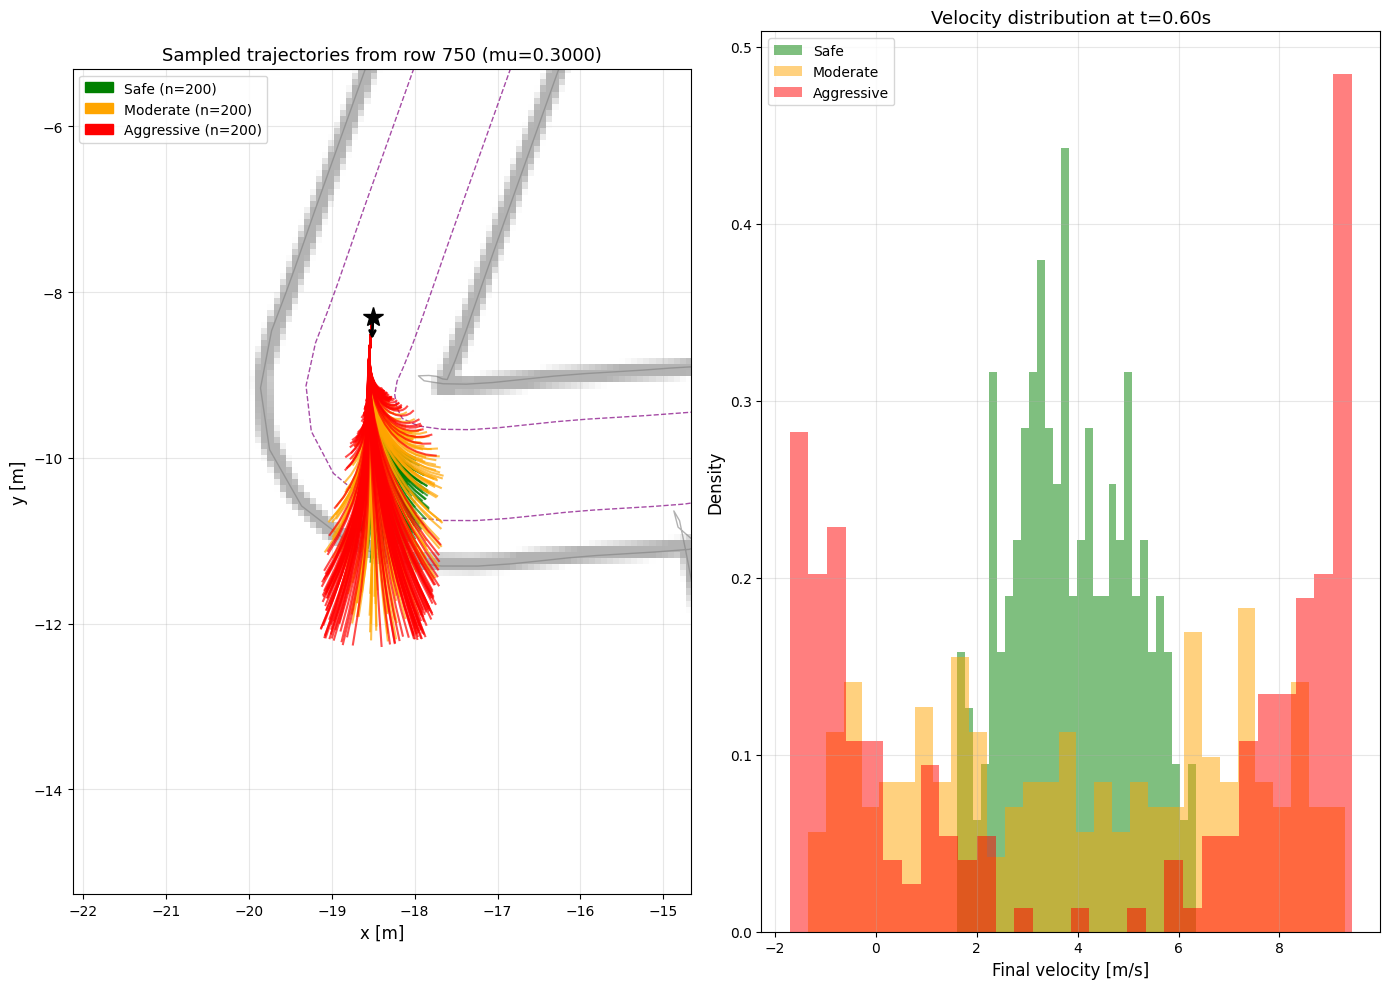


Category         Count  Off-corridor      %  v_end mean  v_end std
----------------------------------------------------------------------
safe               200             0   0.0%        3.89       1.17
moderate           200             3   1.5%        4.00       3.12
aggressive         200             9   4.5%        4.30       4.48


: 

In [ ]:
# ── Low friction (mu = 0.3) ───────────────────────────────────────────
trajs_low, off_low = plot_trajectories(
    ROW_IDX, df, track_obj,
    map_img=map_img, extent=extent,
    mu=0.3, horizon=15, lane_width=1.1,
    n_aggressive=200, n_moderate=200, n_safe=200,
)

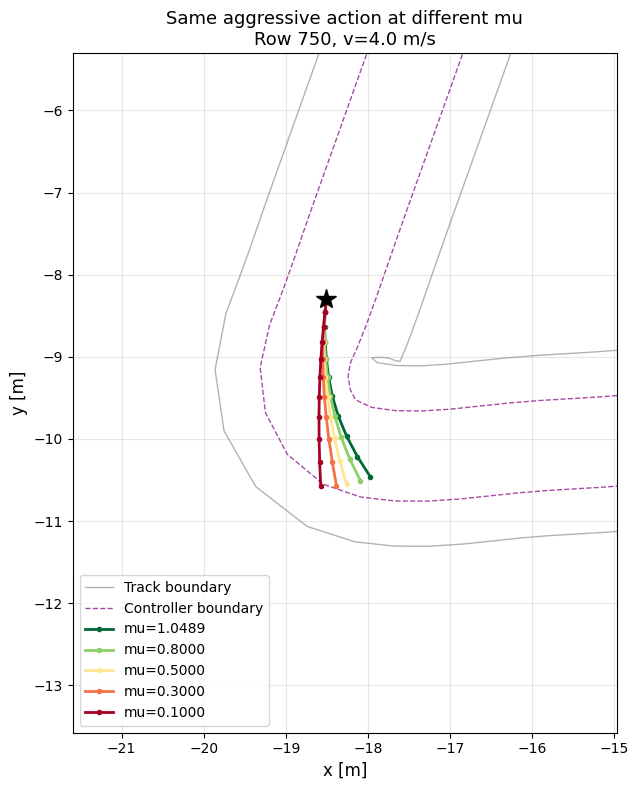

In [11]:
# ── Side-by-side: same aggressive action at different friction ─────────

row = df.iloc[ROW_IDX]
state0 = np.array([
    row.S_x, row.S_y, row.S_delta, row.S_vel,
    row.S_psi, row.S_omega, row.S_beta
])

# Full throttle + hard left
aggressive_action = [(VP['a_max'], VP['sv_max'])] * 10

mu_values = [1.0489, 0.8, 0.5, 0.3, 0.1]
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

# Track boundaries
ax.plot(track_obj.left_boundary[:, 0], track_obj.left_boundary[:, 1],
        '-', color='gray', linewidth=1.0, alpha=0.6, label='Track boundary')
ax.plot(track_obj.right_boundary[:, 0], track_obj.right_boundary[:, 1],
        '-', color='gray', linewidth=1.0, alpha=0.6)
half_lw = 1.1 / 2.0
ctrl_left = track_obj.centerline + track_obj.normal * half_lw
ctrl_right = track_obj.centerline - track_obj.normal * half_lw
ax.plot(ctrl_left[:, 0], ctrl_left[:, 1],
        '--', color='purple', linewidth=1.0, alpha=0.7, label='Controller boundary')
ax.plot(ctrl_right[:, 0], ctrl_right[:, 1],
        '--', color='purple', linewidth=1.0, alpha=0.7)

cmap = plt.cm.RdYlGn  # Red=low friction, Green=high friction
mu_min, mu_max = min(mu_values), max(mu_values)

for mu_val in mu_values:
    traj = rollout(state0, aggressive_action, dt=DT, mu=mu_val)
    color = cmap((mu_val - mu_min) / (mu_max - mu_min))
    ax.plot(traj[:, 0], traj[:, 1], 'o-', color=color, linewidth=2, markersize=3,
            label=f'mu={mu_val:.4f}')

ax.plot(state0[0], state0[1], '*', color='black', markersize=15, zorder=10)

all_trajs = [rollout(state0, aggressive_action, dt=DT, mu=m) for m in mu_values]
all_x = np.concatenate([t[:, 0] for t in all_trajs])
all_y = np.concatenate([t[:, 1] for t in all_trajs])
pad = 3.0
ax.set_xlim(all_x.min() - pad, all_x.max() + pad)
ax.set_ylim(all_y.min() - pad, all_y.max() + pad)
ax.set_aspect('equal')
ax.legend(fontsize=10)
ax.set_title(f'Same aggressive action at different mu\nRow {ROW_IDX}, v={state0[3]:.1f} m/s', fontsize=13)
ax.set_xlabel('x [m]', fontsize=12)
ax.set_ylabel('y [m]', fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()